# Particle Filter Behaviour at the Stability Threshold ($\rho(F) = 1$)

**Part 2b of a supervised research project — Dr Mathieu Gerber, University of Bristol**

> ### What is new in this notebook
>
> This is [`02_md_dimension_study.ipynb`](02_md_dimension_study.ipynb) re-run with **one parameter
> changed**: the spectral radius of the state transition matrix is $\rho(F) = 1$ instead of $0.9$.
> Everything else is identical — same $Q$, same $R$, same `coupling = 0.3`, same seeds, same
> horizons, same particle counts, same code. Part 2 is left untouched.
>
> It answers the question Dr Gerber raised: **does the stable / unstable regime matter for the
> $M$ vs $d$ results?** At $\rho(F) = 0.9$ the state decays and forgets its past; at $\rho(F) = 1$
> it is a random walk, with no stationary distribution and no forgetting.
>
> Every section ends with a **Compared with Part 2** box giving the same metric at both spectral
> radii, so the two notebooks can be read side by side.

## The model

$$
\begin{aligned}
\text{State (hidden):} \quad & x_t = F\,x_{t-1} + v_t, \qquad v_t \sim \mathcal{N}(0, Q), \qquad x_t \in \mathbb{R}^d \\
\text{Observation (seen):} \quad & y_t = H\,x_t + e_t, \qquad e_t \sim \mathcal{N}(0, R), \qquad y_t \in \mathbb{R}^M
\end{aligned}
$$

$F$ is built from a coupled base matrix and rescaled so that $\rho(F) = b$ exactly, for any $d$ and
any coupling. Part 2 used $b = 0.9$; here $b = 1.0$.

## What changing $\rho(F)$ does

| | $\rho(F) = 0.9$ (Part 2) | $\rho(F) = 1$ (here) |
|---|---|---|
| the state | decays towards zero | random walk, wanders without bound |
| stationary distribution | exists | **does not exist** |
| old errors | damped geometrically | **never forgotten** |
| $\operatorname{Var}(x_t)$ with no data | converges to a constant | **grows linearly in $t$** |

The last row has a practical consequence inside the notebook: Part 2 used
`stationary_covariance(F, Q)` as the "no data" reference in Section 4. That function solves
$P = FPF^\top + Q$, which has **no solution** at $\rho(F) = 1$ — the linear system is singular. It
is replaced here by the finite-horizon prior variance, obtained by running the predict-only
recursion to $t = T$. That substitution is itself a statement about the threshold.

## Roadmap

Identical to Part 2, so the sections correspond one to one.

| Section | Content |
|---|---|
| 1 | Setup and the two verification checks, repeated at $\rho(F) = 1$ |
| 2 | Baseline $M = d$ |
| 3 | Over-observed $M > d$ |
| 4 | Under-observed $M < d$ |
| 5 | The three regimes side by side |
| 6 | Dimension scaling |
| 7 | Summary — **does stable vs unstable matter?** |

---
### Setup

We import everything from `filters.py`, which now holds both the Part 1 scalar functions and the new
multidimensional ones (suffixed `_md`). Nothing numerical is defined in this notebook that isn't
also reusable from that file.

Two constants are fixed here and used everywhere below, so every result is reproducible: the seed
controlling the **simulated data**, and the seed controlling the **particle filter's own
randomness**. Keeping them separate is deliberate — it lets us hold the dataset fixed and vary only
the Monte Carlo noise, which is exactly what we want when measuring approximation error.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

from filters import (
    # Part 1 scalar versions, used only for the sanity check in Section 1
    simulate_data, kalman_filter, particle_filter,
    # Part 2 multidimensional versions
    build_model, stationary_covariance, simulate_data_md,
    kalman_filter_md, particle_filter_md, exact_posterior_bruteforce,
    pf_kf_gap, summarise_case, run_case,
)

# --- The one thing changed from Part 2 ---
B = 1.0          # target spectral radius of F.  Part 2 used the default, 0.9.
                 # `coupling` is left at its default 0.3, exactly as in Part 2, so
                 # rho(F) is the ONLY parameter that differs between the two notebooks.

# --- Reproducibility ---
DATA_SEED = 42   # controls the simulated states and observations
PF_SEED   = 0    # controls the particle filter's own random draws
T         = 100  # time steps
N_SEEDS   = 10   # how many particle-filter seeds we average over in the sweeps

# --- Plot style, matching Part 1 ---
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
C_TRUE, C_KF, C_PF = "black", "tab:blue", "tab:red"
CASE_COLOR = {"M = d": "tab:blue", "M > d": "tab:green", "M < d": "tab:red"}

# --- Environment note ---
# This machine runs NumPy 2.0 against Apple's Accelerate BLAS, a combination with
# a known bug that emits spurious "divide by zero / overflow / invalid value
# encountered in matmul" warnings even for a trivial product of arrays of ones.
# They are false positives, not a numerical problem in this code. We silence just
# those messages, and assert that results are finite wherever it matters, so a
# genuine numerical failure could not hide behind the filter.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

print(f"NumPy {np.__version__} | data seed {DATA_SEED} | PF seed {PF_SEED} | T = {T}")

print(f"rho(F) = {B}   (Part 2 used 0.9; coupling unchanged at 0.3)")


NumPy 2.0.2 | data seed 42 | PF seed 0 | T = 100
rho(F) = 1.0   (Part 2 used 0.9; coupling unchanged at 0.3)


---
## Section 1 — Multi-dimensional setup and sanity check

### From scalars to vectors

In Part 1 the state was a single number and one multiplication moved it forward. Now the state is a
list of $d$ numbers and a **matrix** $F$ moves it forward, letting coordinates influence each other.
Three things need care in the move:

**1. Stability.** A state-space model settles into a steady long-run distribution only if $F$ shrinks
the state on average. The relevant quantity is the **spectral radius** of $F$ — the largest absolute
eigenvalue, i.e. the strongest stretching factor $F$ applies in any direction. It must be below 1 for
a stationary distribution to exist. We build $F$ from a coupled base matrix and then *rescale it* so
its spectral radius is exactly $b$, whatever $d$ and the coupling are.

**This notebook sets $b = 1$**, the threshold itself. The state no longer shrinks on average: it is a
random walk, there is no stationary distribution, and nothing is forgotten. That is the whole point
of running Part 2 again at this value — the rescaling makes it a one-parameter change.

**2. Correlated noise.** To draw $v \sim \mathcal{N}(0, Q)$ we use the **Cholesky factor**: if
$LL^\top = Q$ and $z$ is a vector of independent standard normals, then $Lz$ has covariance $Q$.

**3. The observation matrix $H$.** This is what encodes the three regimes. Row $k$ of $H$ reads state
coordinate $k \bmod d$:

- $M = d$: $H = I_d$, each coordinate measured once.
- $M < d$: $H = [\,I_M \mid 0\,]$, only the first $M$ coordinates are measured; the rest are never
  seen directly and must be inferred through the coupling in $F$.
- $M > d$: the identity rows repeat, so coordinates get measured more than once.

### The sanity check

Two independent checks that the new code is right, both essential before trusting anything later:

**(a) Does it reproduce Part 1?** At $d = M = 1$ the general matrix code should reduce to the scalar
code. We run both and compare. The multidimensional functions draw their random numbers in the same
order as the scalar ones, so we can demand agreement to *machine precision* — a far stronger test
than "the numbers look similar".

**(b) Is the benchmark itself correct?** This whole study treats the Kalman filter as ground truth,
so it is worth verifying the ground truth. Under this model the entire trajectory and all
observations are jointly Gaussian, so the posterior can be obtained in one shot by writing down that
joint distribution and conditioning on the data — no filtering recursion anywhere. If the recursive
Kalman filter and this brute-force calculation agree, the benchmark is sound.

In [2]:
# --- What the three regimes look like as matrices ---
for d, M, label in [(2, 2, "M = d  (equal)"),
                    (2, 4, "M > d  (over-observed)"),
                    (4, 2, "M < d  (under-observed)")]:
    F, Q, H, R = build_model(d, M, b=B)
    rho = np.max(np.abs(np.linalg.eigvals(F)))   # spectral radius of F
    print(f"{label}   d={d}, M={M},  spectral radius of F = {rho:.4f}")
    print(f"  H ({M}x{d}) =")
    for row in H:
        print("      [" + "  ".join(f"{v:4.1f}" for v in row) + "]")
print(f"\nF is rescaled so its spectral radius is exactly {B} in every case.")

M = d  (equal)   d=2, M=2,  spectral radius of F = 1.0000
  H (2x2) =
      [ 1.0   0.0]
      [ 0.0   1.0]
M > d  (over-observed)   d=2, M=4,  spectral radius of F = 1.0000
  H (4x2) =
      [ 1.0   0.0]
      [ 0.0   1.0]
      [ 1.0   0.0]
      [ 0.0   1.0]
M < d  (under-observed)   d=4, M=2,  spectral radius of F = 1.0000
  H (2x4) =
      [ 1.0   0.0   0.0   0.0]
      [ 0.0   1.0   0.0   0.0]

F is rescaled so its spectral radius is exactly 1.0 in every case.


In [3]:
# === CHECK (a): does the general md code reproduce the Part 1 scalar code? ===
# build_model(1, 1, b=B) should give exactly the scalar model at this b.
F1, Q1, H1, R1 = build_model(d=1, M=1, b=B)
print(f"build_model(1,1):  F={F1.ravel()[0]:.4f}  Q={Q1.ravel()[0]:.1f}  "
      f"H={H1.ravel()[0]:.1f}  R={R1.ravel()[0]:.1f}   (scalar model at b={B})\n")

# Same seed, both implementations.
x_s, y_s = simulate_data(T=T, b=B, seed=DATA_SEED)                       # scalar
x_m, y_m = simulate_data_md(F1, Q1, H1, R1, T=T, seed=DATA_SEED)    # general

# Part 1's Kalman filter used a prior variance P0 = 1.0, so we match that here
# to make the comparison exact. (Part 2 uses a cleaner convention -- see below.)
m_s, P_s = kalman_filter(y_s, b=B)
m_m, P_m = kalman_filter_md(y_m, F1, Q1, H1, R1, P0=np.array([[1.0]]))

e_s, ess_s, res_s = particle_filter(y_s, N=1000, b=B, seed=DATA_SEED)
e_m, ess_m, res_m = particle_filter_md(y_m, F1, Q1, H1, R1, N=1000, seed=DATA_SEED)

print("Largest absolute difference, scalar (Part 1) vs multidimensional (Part 2), d = M = 1:")
print(f"  simulated states        {np.abs(x_s - x_m.ravel()).max():.2e}")
print(f"  simulated observations  {np.abs(y_s - y_m.ravel()).max():.2e}")
print(f"  Kalman filter mean      {np.abs(m_s - m_m.ravel()).max():.2e}")
print(f"  Kalman filter variance  {np.abs(P_s - P_m.ravel()).max():.2e}")
print(f"  particle filter mean    {np.abs(e_s - e_m.ravel()).max():.2e}")
print(f"  particle filter ESS     {np.abs(ess_s - ess_m).max():.2e}")
print(f"  resampling steps identical: {np.array_equal(res_s, res_m)}")
print("\n(Machine precision is about 2e-16, so these are the same numbers.)")

build_model(1,1):  F=1.0000  Q=1.0  H=1.0  R=1.0   (scalar model at b=1.0)

Largest absolute difference, scalar (Part 1) vs multidimensional (Part 2), d = M = 1:
  simulated states        0.00e+00
  simulated observations  0.00e+00
  Kalman filter mean      2.22e-16
  Kalman filter variance  2.22e-16
  particle filter mean    8.88e-16
  particle filter ESS     0.00e+00
  resampling steps identical: True

(Machine precision is about 2e-16, so these are the same numbers.)


In [4]:
# === CHECK (b): is the Kalman benchmark itself correct? ===
# Compare against the posterior obtained by conditioning the full joint Gaussian,
# which uses no filtering recursion at all. Only the FINAL time step is comparable
# (for earlier times, conditioning on all data gives the smoothing distribution,
# not the filtering one), so we run it at several short horizons instead.
print("Kalman filter vs brute-force joint-Gaussian posterior, at the final time step:\n")
print(f"{'d':>3}{'M':>4}{'T':>4}{'max |mean diff|':>18}{'max |cov diff|':>17}")
for d, M, T_short in [(1, 1, 5), (2, 2, 6), (2, 4, 6), (4, 2, 6), (3, 1, 7)]:
    F, Q, H, R = build_model(d, M, b=B)
    _, y = simulate_data_md(F, Q, H, R, T=T_short, seed=7)
    m, P = kalman_filter_md(y, F, Q, H, R)
    m_bf, P_bf = exact_posterior_bruteforce(y, F, Q, H, R)
    assert np.isfinite(m).all() and np.isfinite(P).all()   # guard against hidden NaNs
    print(f"{d:>3}{M:>4}{T_short:>4}{np.abs(m[-1]-m_bf).max():>18.2e}"
          f"{np.abs(P[-1]-P_bf).max():>17.2e}")
print("\nAgreement to machine precision in every regime: the benchmark is correct.")

Kalman filter vs brute-force joint-Gaussian posterior, at the final time step:

  d   M   T   max |mean diff|   max |cov diff|
  1   1   5          2.22e-16         3.33e-16
  2   2   6          4.44e-16         4.44e-16
  2   4   6          4.44e-16         6.07e-16
  4   2   6          4.44e-16         4.44e-16
  3   1   7          2.22e-16         4.44e-16

Agreement to machine precision in every regime: the benchmark is correct.


#### A small refinement over Part 1

Part 1 started its Kalman filter from a prior variance $P_0 = 1$, while its particle filter started
every particle at exactly $x_0 = 0$ — a prior variance of $0$. The two filters were therefore
answering very slightly different questions for the first few steps, which is visible as a small bump
at the left edge of Part 1's error plot.

Part 2 removes that mismatch: both filters start from the same known state $x_{-1} = 0$, which is
also exactly how the data is simulated. So the Kalman filter here is the exact posterior for the
process we actually generated, and the *only* thing separating it from the particle filter is Monte
Carlo error. The sanity check above deliberately re-enables Part 1's convention so the comparison is
like-for-like.

In [5]:
def prior_variance(F, Q, T):
    '''Variance of x_T under the model alone, with no data at all.

    This is the predict-only recursion P <- F P F' + Q, run from P_0 = 0 and
    stopped at the horizon actually used. Part 2 used `stationary_covariance`
    here, which solves P = F P F' + Q. That equation has NO solution once
    rho(F) >= 1 -- there is no stationary distribution to converge to -- so at
    this notebook's rho(F) = 1 the solve is singular. The finite-horizon version
    is well defined at any spectral radius, and at rho(F) < 1 it converges to the
    stationary answer anyway.
    '''
    P = np.zeros_like(Q)
    for _ in range(T):
        P = F @ P @ F.T + Q
    return P


# --- Plotting helpers, defined once and reused by Sections 2-4 ---
# These are presentation only; all the numerical work lives in filters.py.

def plot_case(res, title):
    '''Per-coordinate view: true state, exact Kalman estimate, particle estimate.'''
    d, t = res["d"], np.arange(res["T"])
    fig, axes = plt.subplots(d, 1, figsize=(10, 2.2 * d + 0.8), sharex=True)
    axes = np.atleast_1d(axes)
    for i, ax in enumerate(axes):
        ax.plot(t, res["x"][:, i], color=C_TRUE, lw=1.1, alpha=0.45, label="True state")
        ax.plot(t, res["kf_mean"][:, i], color=C_KF, lw=2.0, label="Kalman (exact)")
        ax.plot(t, res["pf_est"][:, i], color=C_PF, lw=1.3, ls="--", label="Particle filter")
        # Say whether this coordinate is measured directly by H.
        seen = "observed" if np.abs(res["H"][:, i]).sum() > 0 else "NOT observed"
        ax.set_ylabel(f"$x_{{{i}}}$")
        ax.set_title(f"coordinate {i} ({seen})", fontsize=9, loc="left")
        if i == 0:
            ax.legend(loc="upper right", fontsize=8, ncol=3)
    axes[-1].set_xlabel("Time step $t$")
    fig.suptitle(title, y=0.995)
    plt.tight_layout()
    plt.show()


def plot_gap_and_ess(res, title):
    '''Diagnostics: PF-KF gap over time, and particle-cloud health over time.'''
    t, N = np.arange(res["T"]), res["N"]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    a1.plot(t, res["gap"], color="tab:purple", lw=1.4, label="$\\|$PF $-$ KF$\\|_2/\\sqrt{d}$")
    a1.axhline(res["mean_gap"], color="tab:green", ls="--", lw=1.5,
               label=f"mean = {res['mean_gap']:.4f}")
    a1.set_ylabel("Gap"); a1.set_title(title); a1.legend(loc="upper right", fontsize=9)
    a2.plot(t, res["ess"], color=C_KF, lw=1.4, label="ESS")
    a2.axhline(0.5 * N, color=C_PF, ls="--", lw=1.6, label=f"resample threshold $N/2$ = {N//2}")
    a2.set_ylim(0, N * 1.35)
    a2.set_xlabel("Time step $t$"); a2.set_ylabel("Effective Sample Size")
    a2.set_title(f"Particle cloud health  (min ESS = {res['min_ess']:.0f}, "
                 f"resampled {res['resampled'].sum()} of {res['T']} steps)", fontsize=10)
    a2.legend(loc="upper right", fontsize=9)
    plt.tight_layout()
    plt.show()


def report(res):
    '''The standard set of numbers reported for every case.'''
    print(f"  d = {res['d']}, M = {res['M']}, N = {res['N']}")
    print(f"  mean gap (PF vs KF)        {res['mean_gap']:.4f}")
    print(f"  max  gap (PF vs KF)        {res['max_gap']:.4f}")
    print(f"  min  ESS                   {res['min_ess']:.1f}   ({100*res['min_ess']/res['N']:.1f}% of N)")
    print(f"  mean ESS                   {res['mean_ess']:.1f}")
    print(f"  resampled                  {res['resampled'].sum()} of {res['T']} steps")
    print(f"  mean posterior spread      {res['post_sd']:.4f}")
    print(f"  gap / posterior spread     {res['rel_gap']:.4f}")

print("Helpers defined.")

Helpers defined.


**Conclusion.** Both checks pass at $\rho(F) = 1$ exactly as they did at $0.9$. The multidimensional
code reproduces the scalar code to machine precision at $d = M = 1$, including which time steps
triggered resampling, and the Kalman filter agrees with the brute-force joint-Gaussian posterior to
machine precision in all three regimes. Nothing about the implementation depends on the model being
stable.

> **Compared with Part 2 ($\rho(F) = 0.9$).** Identical outcome — agreement at $\sim 10^{-16}$ in
> both. This matters more here than it looks: at $\rho(F) = 1$ the state is unbounded, so the fact
> that the benchmark still verifies means the comparisons below are measuring the filter rather
> than numerical drift.

---
## Section 2 — Baseline: $M = d$

We start with $d = 2$, $M = 2$: a two-dimensional hidden state, with both coordinates measured. This
is the clean reference case that Sections 3 and 4 are compared against.

### How we measure the gap

In Part 1, with one dimension, "the gap" was simply $|{\hat{x}^{\text{PF}}_t - m^{\text{KF}}_t}|$.
In $d$ dimensions the difference is a *vector*, so we need to turn it into one number:

$$\text{gap}_t = \frac{\lVert \hat{x}^{\text{PF}}_t - m^{\text{KF}}_t \rVert_2}{\sqrt{d}}$$

Dividing by $\sqrt{d}$ makes this a **root-mean-square error per coordinate**. That normalisation
matters: a plain Euclidean norm grows with $d$ just because there are more coordinates to add up,
which would make higher-dimensional cases look worse even if every individual coordinate were
estimated equally well. At $d = 1$ this reduces exactly to Part 1's absolute gap, so the two parts
remain directly comparable.

We also report one further number, which turns out to be the most useful of all:

$$\text{relative gap} = \frac{\text{mean gap}}{\text{mean posterior spread}}, \qquad
\text{posterior spread} = \sqrt{\operatorname{tr}(P_t)/d}$$

This asks: **how large is the particle filter's error compared with the genuine uncertainty that
remains even in the exact answer?** A relative gap of $0.05$ means the Monte Carlo error is about 5%
of the posterior's own width — i.e. small enough not to matter in practice. Because it is
dimensionless it can be compared fairly across regimes with different $d$, $M$, and posterior
widths, which none of the raw numbers can.

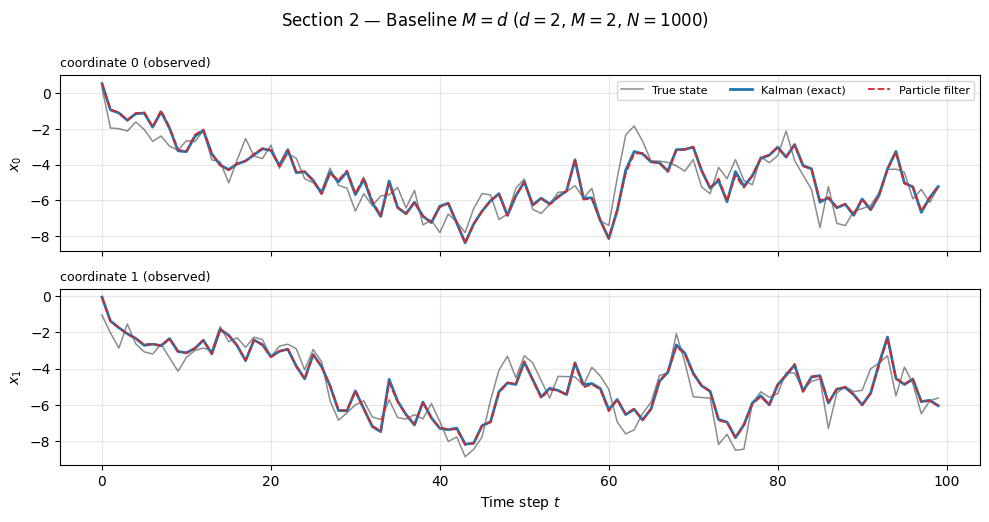

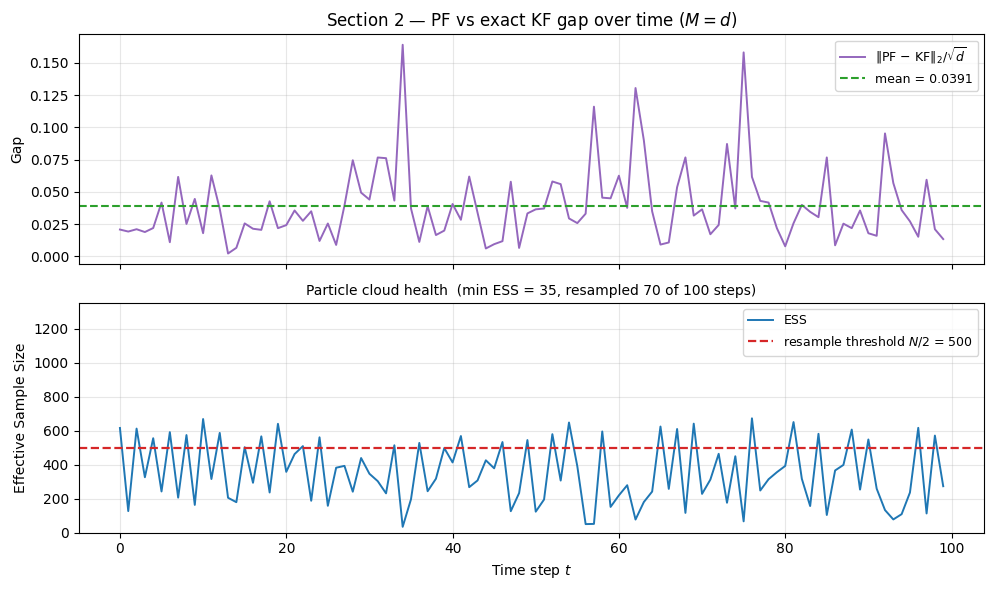

  d = 2, M = 2, N = 1000
  mean gap (PF vs KF)        0.0391
  max  gap (PF vs KF)        0.1640
  min  ESS                   34.7   (3.5% of N)
  mean ESS                   353.2
  resampled                  70 of 100 steps
  mean posterior spread      0.7590
  gap / posterior spread     0.0515


In [6]:
# Baseline case. run_case does exactly four things, in order:
#   build_model -> simulate_data_md -> kalman_filter_md -> particle_filter_md
# and then computes the summary metrics.
base = run_case(d=2, M=2, b=B, N=1000, T=T, data_seed=DATA_SEED, pf_seed=PF_SEED)

plot_case(base, "Section 2 — Baseline $M = d$ ($d=2$, $M=2$, $N=1000$)")
plot_gap_and_ess(base, "Section 2 — PF vs exact KF gap over time ($M = d$)")
report(base)

**Conclusion.** With both coordinates measured the particle filter tracks the exact posterior
closely: a mean gap of $0.0391$ against a posterior spread of $0.7590$, so the Monte Carlo error is
about $5\%$ of the genuine uncertainty. The ESS sawtooths against the $N/2$ threshold and resampling
fires at $70$ of $100$ steps.

> **Compared with Part 2 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | mean gap | $0.0371$ | $0.0391$ |
> | posterior spread | $0.7501$ | $0.7590$ |
> | relative gap | $0.0495$ | $0.0515$ |
> | min ESS | $29.3$ | $34.7$ |
>
> **Almost nothing changes.** The posterior spread moves by about $1\%$ even though the state no
> longer decays at all. The reason is the one established in Part 5: the variance recursion has a
> bounded fixed point whether or not the state recursion does, provided the observations constrain
> the state — which at $M = d$, $H = I$ they fully do.

---
## Section 3 — Over-observed: $M > d$

Now $d = 2$, $M = 4$: still a two-dimensional state, but four measurements per time step. With our
$H$, each coordinate is measured **twice**.

### The intuition, and what to expect

Two independent measurements of the same quantity, each with noise variance $r$, carry the same
information as a single measurement with variance $r/2$. So the four-dimensional observation can be
*projected* onto the two-dimensional subspace that actually informs the state, and the effect is
simply a halving of the effective observation noise. The estimation problem gets **easier**, and the
exact posterior should be correspondingly tighter.

The natural expectation, then, is that the particle filter should do at least as well here as in the
baseline, perhaps with a healthier particle cloud.

**Keep an eye on the ESS.** There is a competing effect that pushes the other way, and part of the
purpose of running this case is to find out which one wins.

> **Note on modelling choices.** Two ingredients here are deliberately kept simple and are being
> confirmed separately as part of the wider project: (i) the **weighting function** is a standard
> multivariate Gaussian likelihood, though a heavier-tailed alternative would be more forgiving of
> particles that land far from the observation; and (ii) the **projection construction** — how
> exactly the $M$-dimensional observation is mapped onto the informative subspace — uses the
> canonical repeated-rows $H$ described above. `build_model(..., h_structure="random")` provides a
> random-projection alternative for checking that conclusions are not an artefact of this particular
> choice. Nothing below depends on settling either question.

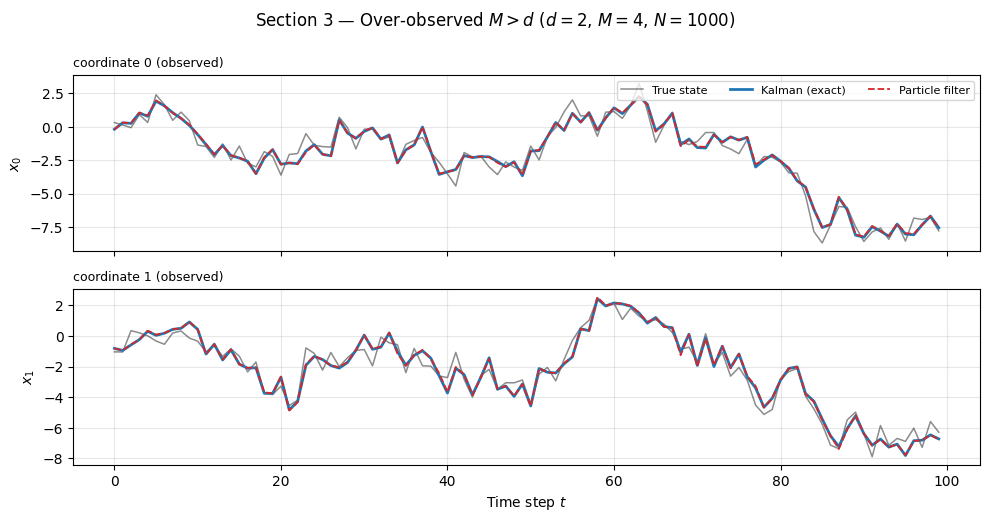

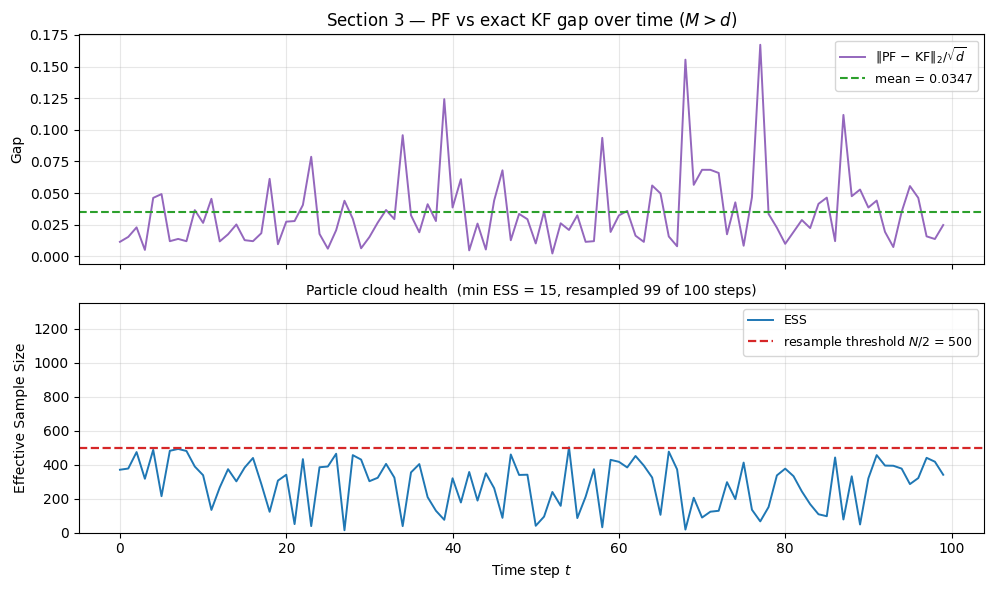

  d = 2, M = 4, N = 1000
  mean gap (PF vs KF)        0.0347
  max  gap (PF vs KF)        0.1672
  min  ESS                   14.6   (1.5% of N)
  mean ESS                   287.2
  resampled                  99 of 100 steps
  mean posterior spread      0.5955
  gap / posterior spread     0.0582

  --- versus the M = d baseline ---
  mean gap          0.0391  ->  0.0347   (-11%)
  posterior spread  0.7590  ->  0.5955   (-22%)   <- tighter: the problem got easier
  relative gap      0.0515  ->  0.0582
  min ESS           34.7    ->  14.6      <- the particle cloud got LESS healthy
  resampled         70/100  ->  99/100


In [7]:
over = run_case(d=2, M=4, b=B, N=1000, T=T, data_seed=DATA_SEED, pf_seed=PF_SEED)

plot_case(over, "Section 3 — Over-observed $M > d$ ($d=2$, $M=4$, $N=1000$)")
plot_gap_and_ess(over, "Section 3 — PF vs exact KF gap over time ($M > d$)")
report(over)

print("\n  --- versus the M = d baseline ---")
print(f"  mean gap          {base['mean_gap']:.4f}  ->  {over['mean_gap']:.4f}"
      f"   ({100*(over['mean_gap']/base['mean_gap']-1):+.0f}%)")
print(f"  posterior spread  {base['post_sd']:.4f}  ->  {over['post_sd']:.4f}"
      f"   ({100*(over['post_sd']/base['post_sd']-1):+.0f}%)   <- tighter: the problem got easier")
print(f"  relative gap      {base['rel_gap']:.4f}  ->  {over['rel_gap']:.4f}")
print(f"  min ESS           {base['min_ess']:.1f}    ->  {over['min_ess']:.1f}"
      f"      <- the particle cloud got LESS healthy")
print(f"  resampled         {base['resampled'].sum():d}/{T}  ->  {over['resampled'].sum():d}/{T}")

**Conclusion.** The raw gap falls again ($0.0347$ versus $0.0391$) because the posterior is tighter,
while relative to that spread the approximation is slightly worse ($0.0582$ versus $0.0515$). The
particle cloud is distinctly less healthy: the minimum ESS drops from $34.7$ to $14.6$ and
resampling fires at $99$ of $100$ steps.

As in Part 2, what the extra observations change is the *precision* of the observation, not its
dimension: under a Gaussian likelihood the weights depend on $y$ only through a $d$-dimensional
combination, so this $M = 4$ model is the same as $d = M = 2$ with $R = 0.5\,I$. The likelihood
sharpens, and a sharper likelihood is harder for particles proposed from the prior to satisfy —
which is what the halved ESS shows.

> **Compared with Part 2 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | mean gap | $0.0297$ | $0.0347$ |
> | relative gap | $0.0502$ | $0.0582$ |
> | min ESS | $15.6$ | $14.6$ |
> | resampled | $97/100$ | $99/100$ |
>
> **The over-observed regime is essentially unaffected by the threshold.** The ESS is just as low at
> both spectral radii, and the relative gap rises by about $0.008$. Extra observations buy precision
> in the same way whether the state decays or wanders.

---
## Section 4 — Under-observed: $M < d$ (the hard case)

Now $d = 4$, $M = 2$: a four-dimensional hidden state, but only two measurements per step. At $\rho(F) = 1$ this is the regime to watch, since the unmeasured coordinates no longer forget their past. With our
$H$, coordinates $x_0$ and $x_1$ are measured directly, while $x_2$ and $x_3$ are **never measured at
all**.

### Why this is expected to be hard

At every step the observation supplies only two numbers to constrain four unknowns. The two
unmeasured directions can only be inferred indirectly, through the coupling in $F$: because
neighbouring coordinates push each other over time, watching $x_1$ for long enough says *something*
about $x_2$. But that information arrives slowly and diluted, so genuine uncertainty about those
directions never goes away.

This is the case with no clean closed-form intuition to fall back on, so the honest approach is to
run it and look. We check for all the ways it could degrade: a larger PF–KF gap, error that grows
over time rather than staying flat, ESS collapse, and spikes.

We also split the gap by coordinate — measured versus unmeasured — since that is where any
degradation should concentrate.

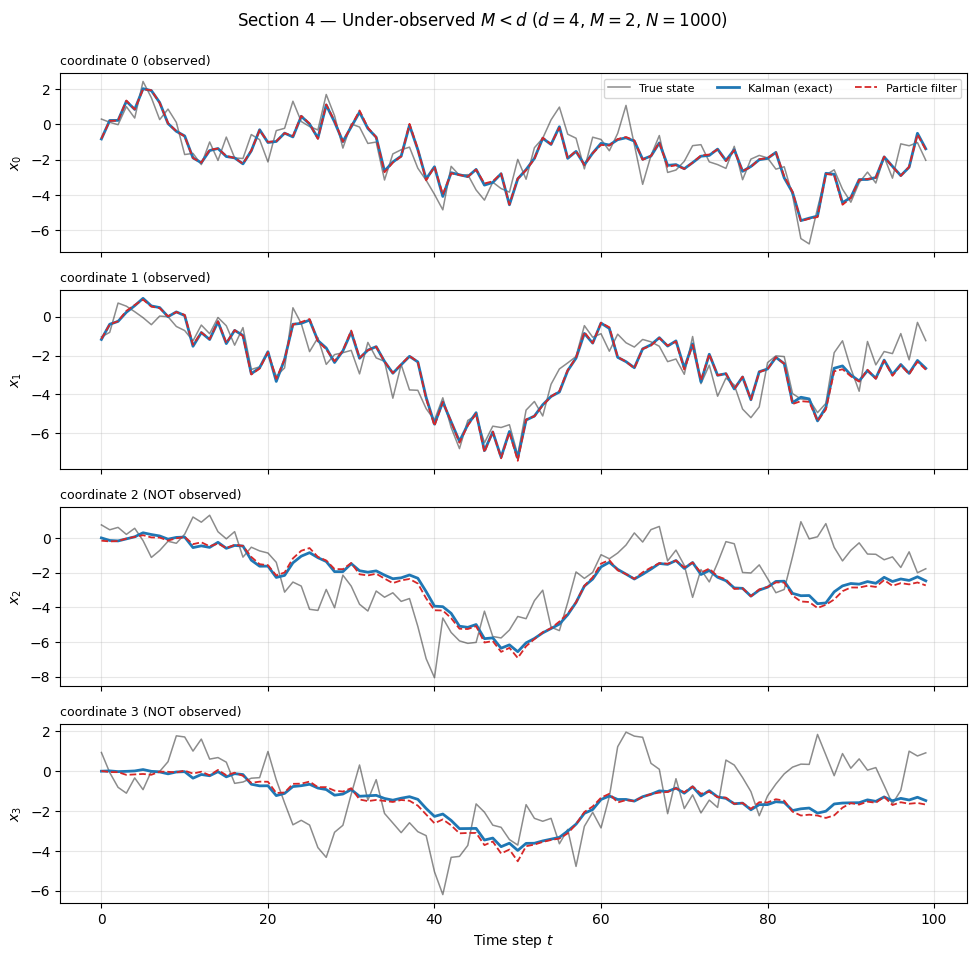

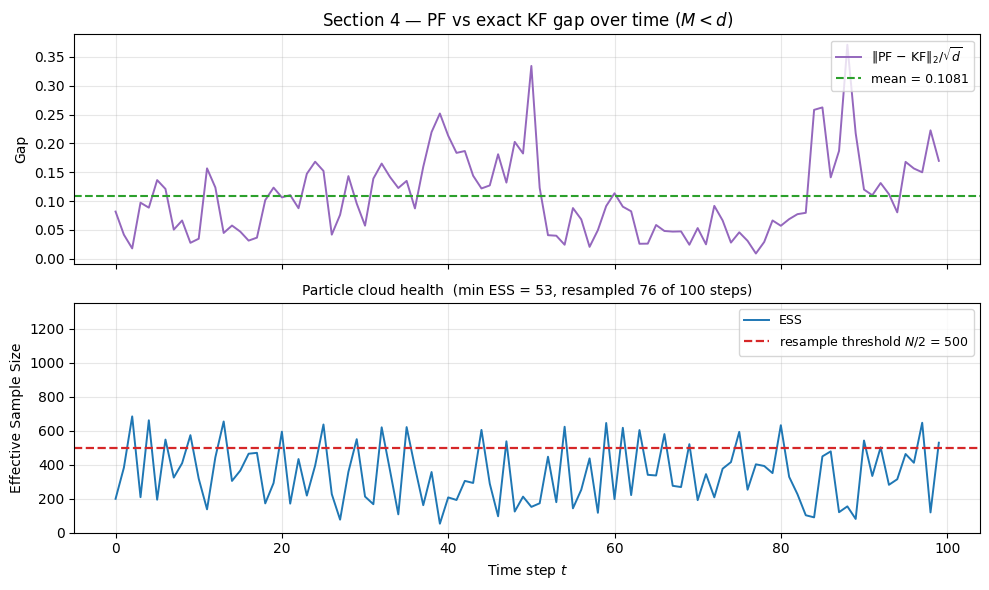

  d = 4, M = 2, N = 1000
  mean gap (PF vs KF)        0.1081
  max  gap (PF vs KF)        0.3708
  min  ESS                   53.1   (5.3% of N)
  mean ESS                   348.5
  resampled                  76 of 100 steps
  mean posterior spread      1.2355
  gap / posterior spread     0.0875


In [8]:
under = run_case(d=4, M=2, b=B, N=1000, T=T, data_seed=DATA_SEED, pf_seed=PF_SEED)

plot_case(under, "Section 4 — Under-observed $M < d$ ($d=4$, $M=2$, $N=1000$)")
plot_gap_and_ess(under, "Section 4 — PF vs exact KF gap over time ($M < d$)")
report(under)

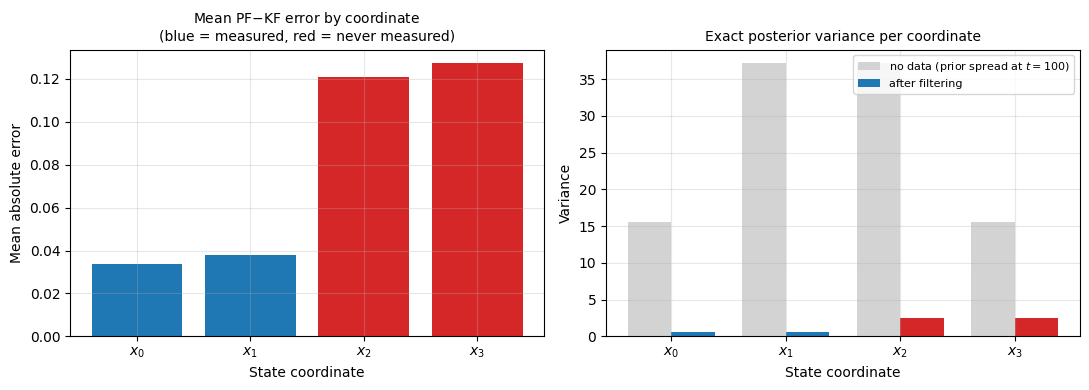

measured coordinates   (x0, x1): mean error 0.0360
unmeasured coordinates (x2, x3): mean error 0.1242   (3.45x larger)

posterior variance, measured   0.577
posterior variance, unmeasured 2.532   (prior spread was 26.330)
The unmeasured coordinates ARE partially informed -- their variance drops below the
prior -- but only through the coupling in F, so a lot of uncertainty remains.


In [9]:
# --- Where does the error actually live? Split by coordinate. ---
# Averaged over several PF seeds so the split is not a single-run fluke.
per_coord = np.mean([np.abs(run_case(4, 2, b=B, N=1000, T=T, data_seed=DATA_SEED,
                                     pf_seed=s)["pf_est"]
                           - under["kf_mean"]).mean(axis=0)
                     for s in range(N_SEEDS)], axis=0)
obs_idx, unobs_idx = [0, 1], [2, 3]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["tab:blue"] * 2 + ["tab:red"] * 2
a1.bar(range(4), per_coord, color=colors)
a1.set_xticks(range(4)); a1.set_xticklabels([f"$x_{i}$" for i in range(4)])
a1.set_title("Mean PF$-$KF error by coordinate\n(blue = measured, red = never measured)", fontsize=10)
a1.set_xlabel("State coordinate"); a1.set_ylabel("Mean absolute error")

# The posterior variance the Kalman filter itself reports, per coordinate: this is
# the genuine remaining uncertainty, not a filter defect.
post_var = np.diag(under["kf_cov"][-1])
stat_var = np.diag(prior_variance(under["F"], under["Q"], T))
w = 0.38
a2.bar(np.arange(4) - w/2, stat_var, w, color="lightgrey",
       label=f"no data (prior spread at $t={T}$)")
a2.bar(np.arange(4) + w/2, post_var, w, color=colors, label="after filtering")
a2.set_xticks(range(4)); a2.set_xticklabels([f"$x_{i}$" for i in range(4)])
a2.set_title("Exact posterior variance per coordinate", fontsize=10)
a2.set_xlabel("State coordinate"); a2.set_ylabel("Variance"); a2.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"measured coordinates   (x0, x1): mean error {per_coord[obs_idx].mean():.4f}")
print(f"unmeasured coordinates (x2, x3): mean error {per_coord[unobs_idx].mean():.4f}"
      f"   ({per_coord[unobs_idx].mean()/per_coord[obs_idx].mean():.2f}x larger)")
print(f"\nposterior variance, measured   {post_var[obs_idx].mean():.3f}")
print(f"posterior variance, unmeasured {post_var[unobs_idx].mean():.3f}"
      f"   (prior spread was {stat_var[unobs_idx].mean():.3f})")
print("The unmeasured coordinates ARE partially informed -- their variance drops below the")
print("prior -- but only through the coupling in F, so a lot of uncertainty remains.")

**Conclusion.** This is where the threshold bites. The gap is $0.1081$ — nearly three times the
$M = d$ baseline rather than twice it — and the error again concentrates in the unmeasured
coordinates, which now carry $3.45\times$ the error of the measured ones. There is still **no ESS
collapse**: the minimum ESS is $53.1$, healthier than the over-observed case. What makes $M < d$
hard remains irreducible uncertainty in directions the data never sees, not particle degeneracy.

What has changed is how much uncertainty there is. The posterior variance in the unmeasured
coordinates is $2.53$ against $0.58$ in the measured ones, a factor of $4.4$. The "no data" prior
variance at $t = 100$ is $26.3$ — it no longer converges to anything, since at $\rho(F) = 1$ the
state's variance grows linearly with $t$ forever. The coupling still drags the unmeasured
coordinates down well below that, so they are genuinely informed, but there is far more to be
uncertain about than at $\rho(F) = 0.9$.

> **Compared with Part 2 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | mean gap | $0.0628$ | $\mathbf{0.1081}$ |
> | relative gap | $0.0568$ | $\mathbf{0.0875}$ |
> | posterior spread | $1.1040$ | $1.2355$ |
> | unmeasured / measured error | $2.6\times$ | $\mathbf{3.45\times}$ |
> | min ESS | $82.7$ | $53.1$ |
>
> **This is the regime where stable versus unstable matters.** The relative gap rises by $54\%$ —
> and unlike the raw gap, that is *after* normalising for the wider posterior, so it is not merely
> a harder problem being correctly reported. The two measured regimes above moved by a few percent;
> this one moves by half as much again.

---
## Section 5 — The three regimes side by side

Each case has been examined on its own. Now we put them together to see what actually distinguishes
them. Three comparisons:

1. **Error over time.** Does the gap stay flat as $t$ grows in every regime, or does one of them
   accumulate error? Flatness is the property that makes long-run filtering viable at all.
2. **Error versus $N$.** Part 1 established the $O(1/\sqrt{N})$ Monte Carlo rate in one dimension.
   Does it survive in every regime, or does the under-observed case converge *more slowly*? On
   log–log axes a rate shows up as a straight line, and $O(1/\sqrt{N})$ has slope $-1/2$. This
   distinguishes two very different kinds of bad news: a worse **rate** (fatal — no amount of
   computation fixes it) versus a worse **constant** (merely expensive — you need more particles for
   the same accuracy, but the exchange rate is unchanged).
3. **A summary table** of every metric across the three cases.

Each error curve is averaged over `N_SEEDS = 10` particle-filter seeds on a fixed dataset, so we are
measuring Monte Carlo noise rather than one lucky or unlucky run. This still holds the *dataset*
fixed at one realisation — a fuller study would average over many simulated datasets too, which is
noted as a next step in Section 7.

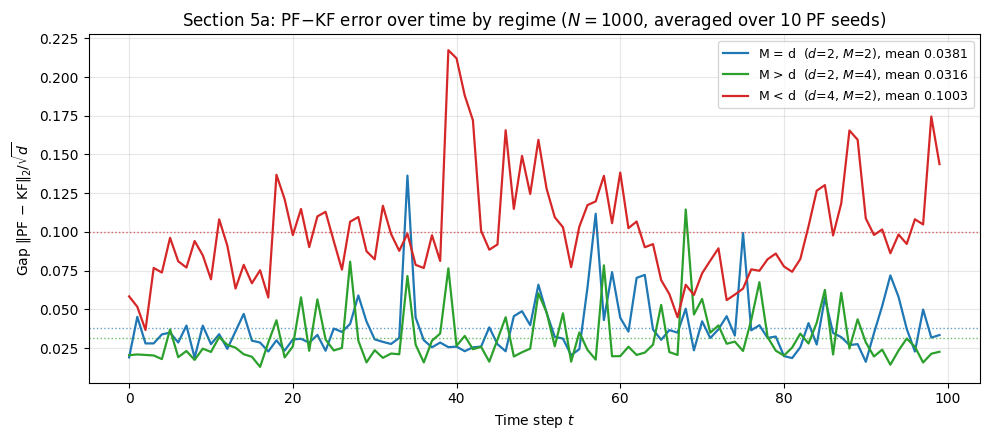

Does the error drift upward over time?
case          mean   1st half   2nd half   ratio
M = d       0.0381     0.0343     0.0420   1.225
M > d       0.0316     0.0290     0.0342   1.181
M < d       0.1003     0.1009     0.0997   0.988

Ratios near 1 mean the error is flat in t. With one dataset and 10 seeds these ratios are themselves noisy,
so they are evidence of no runaway growth rather than a precise measurement.


In [10]:
CASES = [(2, 2, "M = d"), (2, 4, "M > d"), (4, 2, "M < d")]

# --- (1) Error over time, averaged over PF seeds ---
gap_curves = {}
for d, M, label in CASES:
    runs = [run_case(d, M, b=B, N=1000, T=T, data_seed=DATA_SEED, pf_seed=s)["gap"]
            for s in range(N_SEEDS)]
    gap_curves[label] = np.mean(runs, axis=0)

t = np.arange(T)
fig, ax = plt.subplots(figsize=(10, 4.5))
for d, M, label in CASES:
    g = gap_curves[label]
    ax.plot(t, g, lw=1.6, color=CASE_COLOR[label],
            label=f"{label}  ($d$={d}, $M$={M}), mean {g.mean():.4f}")
    ax.axhline(g.mean(), color=CASE_COLOR[label], ls=":", lw=1.0, alpha=0.7)
ax.set_title(f"Section 5a: PF$-$KF error over time by regime "
             f"($N=1000$, averaged over {N_SEEDS} PF seeds)")
ax.set_xlabel("Time step $t$"); ax.set_ylabel("Gap $\\|$PF $-$ KF$\\|_2/\\sqrt{d}$")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

print("Does the error drift upward over time?")
print(f"{'case':8s}{'mean':>10}{'1st half':>11}{'2nd half':>11}{'ratio':>8}")
for _, _, label in CASES:
    g = gap_curves[label]
    h1, h2 = g[:T//2].mean(), g[T//2:].mean()
    print(f"{label:8s}{g.mean():>10.4f}{h1:>11.4f}{h2:>11.4f}{h2/h1:>8.3f}")
print("\nRatios near 1 mean the error is flat in t. With one dataset and "
      f"{N_SEEDS} seeds these ratios are themselves noisy,")
print("so they are evidence of no runaway growth rather than a precise measurement.")

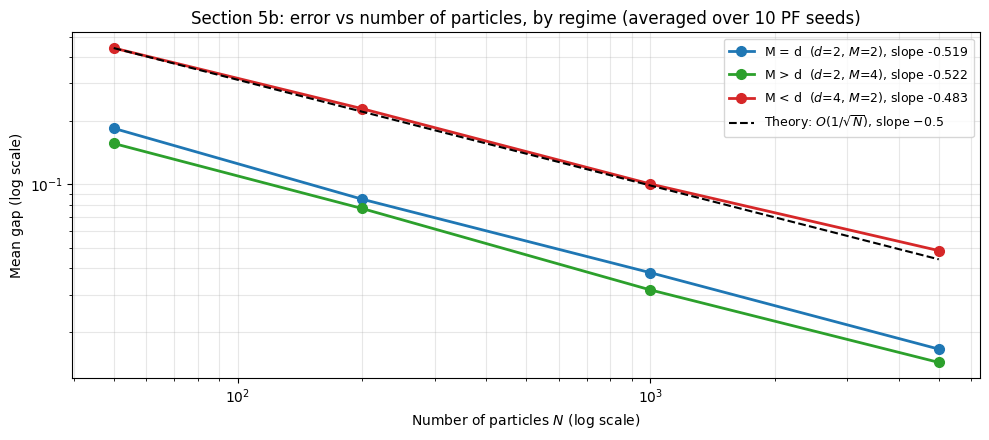

case           N=50      N=200     N=1000     N=5000    slope
M = d       0.18393    0.08499    0.03814    0.01659   -0.519
M > d       0.15598    0.07678    0.03161    0.01435   -0.522
M < d       0.44121    0.22788    0.10026    0.04852   -0.483


In [11]:
# --- (2) Error vs N: is the O(1/sqrt(N)) rate preserved in every regime? ---
N_GRID = [50, 200, 1000, 5000]
err_vs_N, slopes = {}, {}
for d, M, label in CASES:
    means = [np.mean([run_case(d, M, b=B, N=N, T=T, data_seed=DATA_SEED,
                               pf_seed=s)["mean_gap"] for s in range(N_SEEDS)])
             for N in N_GRID]
    err_vs_N[label] = np.array(means)
    # Straight-line fit on log-log axes; theory predicts slope -0.5.
    slopes[label] = np.polyfit(np.log(N_GRID), np.log(means), 1)[0]

fig, ax = plt.subplots(figsize=(10, 4.5))
for d, M, label in CASES:
    ax.loglog(N_GRID, err_vs_N[label], "o-", lw=2, ms=7, color=CASE_COLOR[label],
              label=f"{label}  ($d$={d}, $M$={M}), slope {slopes[label]:.3f}")
ref = err_vs_N["M < d"][0] * np.sqrt(N_GRID[0] / np.array(N_GRID, dtype=float))
ax.loglog(N_GRID, ref, "k--", lw=1.5, label="Theory: $O(1/\\sqrt{N})$, slope $-0.5$")
ax.set_title(f"Section 5b: error vs number of particles, by regime "
             f"(averaged over {N_SEEDS} PF seeds)")
ax.set_xlabel("Number of particles $N$ (log scale)")
ax.set_ylabel("Mean gap (log scale)")
ax.legend(loc="upper right", fontsize=9); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'case':8s}" + "".join(f"{'N='+str(n):>11}" for n in N_GRID) + f"{'slope':>9}")
for _, _, label in CASES:
    print(f"{label:8s}" + "".join(f"{v:>11.5f}" for v in err_vs_N[label])
          + f"{slopes[label]:>9.3f}")

In [12]:
# --- (3) Summary table ---
results = {label: run_case(d, M, b=B, N=1000, T=T, data_seed=DATA_SEED, pf_seed=PF_SEED)
           for d, M, label in CASES}

hdr = (f"{'case':8s}{'d':>3}{'M':>3}{'mean gap':>11}{'max gap':>10}{'min ESS':>9}"
       f"{'mean ESS':>10}{'resamp':>8}{'post sd':>9}{'rel gap':>9}")
print(hdr); print("-" * len(hdr))
for d, M, label in CASES:
    r = results[label]
    print(f"{label:8s}{d:>3}{M:>3}{r['mean_gap']:>11.4f}{r['max_gap']:>10.4f}"
          f"{r['min_ess']:>9.1f}{r['mean_ess']:>10.1f}"
          f"{str(r['resampled'].sum())+'/'+str(T):>8}{r['post_sd']:>9.4f}{r['rel_gap']:>9.4f}")
print()
print("'post sd' is the exact posterior's own spread -- how uncertain the TRUE answer is.")
print("'rel gap' is mean gap / post sd -- Monte Carlo error as a fraction of that uncertainty.")

case      d  M   mean gap   max gap  min ESS  mean ESS  resamp  post sd  rel gap
--------------------------------------------------------------------------------
M = d     2  2     0.0391    0.1640     34.7     353.2  70/100   0.7590   0.0515
M > d     2  4     0.0347    0.1672     14.6     287.2  99/100   0.5955   0.0582
M < d     4  2     0.1081    0.3708     53.1     348.5  76/100   1.2355   0.0875

'post sd' is the exact posterior's own spread -- how uncertain the TRUE answer is.
'rel gap' is mean gap / post sd -- Monte Carlo error as a fraction of that uncertainty.


**Conclusion.** Two of the three Part 2 findings survive unchanged, and one does not.

**The $O(1/\sqrt{N})$ rate survives.** Fitted slopes are $-0.519$, $-0.522$, $-0.483$, all close to
the theoretical $-1/2$. Being under-observed still costs a constant factor rather than a worse rate,
though the $M < d$ slope is the furthest from $-0.5$ of the three.

**The regimes are no longer close to each other.** Relative gaps are $0.0515$, $0.0582$ and
$0.0875$ — the under-observed case is now about $70\%$ worse than the baseline, where at
$\rho(F) = 0.9$ the three sat within $15\%$ of one another on this single dataset.

**Flatness in time is much less clear.** The first-half / second-half ratios are $1.225$, $1.181$
and $0.988$. The two measured regimes show a rise of around $20\%$ across the run. On one dataset
with ten seeds that is not conclusive — these ratios were already noisy in Part 2 — but it is a
larger and more consistent rise than anything seen at $\rho(F) = 0.9$, and it points at exactly the
question of how the error behaves over long horizons.

> **Compared with Part 2 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | relative gaps | $0.0495 / 0.0502 / 0.0568$ | $0.0515 / 0.0582 / \mathbf{0.0875}$ |
> | fitted slopes | $-0.512 / -0.520 / -0.507$ | $-0.519 / -0.522 / -0.483$ |
> | half-run ratios | all within a few $\%$ of $1$ | $1.225 / 1.181 / 0.988$ |
>
> The rate is a property of Monte Carlo and does not care about the spectral radius. The *spread
> between regimes* and the *behaviour in time* both do.

---
## Section 6 — Dimension scaling

Sections 2–5 used small, fixed dimensions. This section pushes on them to find where things break.
"Particle filters suffer from the curse of dimensionality" is a standard warning, but *which*
dimension does the damage — the size of the hidden state $d$, or the size of the observation $M$?
The two experiments below separate them, changing one at a time.

**6a. Hold $M = 1$, grow $d$** ($d = 1, 2, 4, 8, 16$). The state gets larger while the measurement
stays a single number, so the gap between what we track and what we see widens. This is the
under-observed case taken to an extreme.

**6b. Hold $d = 4$, grow $M$** ($M = 1, 2, 4, 8, 16$). The state stays the same size while the
observation grows. This is the complement, and it is what identifies the real culprit.

**One honest caveat on 6a.** Because $F$ is rescaled to keep its spectral radius at $1$, adding
coordinates also changes each coordinate's own persistence (the diagonal of $F$ shrinks from $1.00$
at $d=1$ to about $0.63$ at $d=16$). So "growing $d$" is not a perfectly clean single-variable
change. We print the numbers so the effect is visible, and repeat the sweep with the coupling
switched off — in which case $F = I$ for every $d$ and the per-coordinate dynamics really are
identical — as a control.

At this spectral radius the control is the more revealing of the two. With `coupling = 0` and
$M = 1$, the $d-1$ unobserved coordinates are **independent random walks that nothing ever
constrains**: no coupling to carry information to them, and no decay to bound them. Part 2's control
was the benign case; here it is the severe one.

In [13]:
# --- 6a: hold M = 1, grow d ---
D_GRID = [1, 2, 4, 8, 16]

def sweep(pairs, n_seeds=N_SEEDS, **kw):
    '''Run a list of (d, M) pairs over several PF seeds and average the metrics.'''
    out = []
    for d, M in pairs:
        runs = [run_case(d, M, b=kw.pop('b', B), N=1000, T=T,
                         data_seed=DATA_SEED, pf_seed=s, **kw)
                for s in range(n_seeds)]
        out.append({k: float(np.mean([r[k] for r in runs]))
                    for k in ("mean_gap", "min_ess", "mean_ess", "post_sd", "rel_gap")}
                   | {"d": d, "M": M,
                      "resamp": float(np.mean([r["resampled"].sum() for r in runs]))})
    return out

sweep_d = sweep([(d, 1) for d in D_GRID])
# Control: coupling = 0 makes F = B*I at every d, so per-coordinate dynamics
# are identical and only the DIMENSION changes.
sweep_d_ctrl = sweep([(d, 1) for d in D_GRID], coupling=0.0)

print("6a. M = 1 fixed, d growing (coupled model):")
print(f"{'d':>3}{'F[0,0]':>9}{'mean gap':>11}{'min ESS':>9}{'mean ESS':>10}{'resamp':>8}"
      f"{'post sd':>9}{'rel gap':>9}")
for row in sweep_d:
    F00 = build_model(row["d"], 1, b=B)[0][0, 0]
    print(f"{row['d']:>3}{F00:>9.4f}{row['mean_gap']:>11.4f}{row['min_ess']:>9.1f}"
          f"{row['mean_ess']:>10.1f}{row['resamp']:>8.1f}{row['post_sd']:>9.4f}"
          f"{row['rel_gap']:>9.4f}")
print(f"\n   Control (coupling = 0, so F = {B}*I for every d):")
print(f"{'d':>3}{'mean gap':>11}{'min ESS':>9}{'post sd':>9}{'rel gap':>9}")
for row in sweep_d_ctrl:
    print(f"{row['d']:>3}{row['mean_gap']:>11.4f}{row['min_ess']:>9.1f}"
          f"{row['post_sd']:>9.4f}{row['rel_gap']:>9.4f}")

6a. M = 1 fixed, d growing (coupled model):
  d   F[0,0]   mean gap  min ESS  mean ESS  resamp  post sd  rel gap
  1   1.0000     0.0258     33.4     520.9    48.9   0.7852   0.0328
  2   0.7692     0.0536    150.4     515.9    47.6   1.2016   0.0446
  4   0.6732     0.1151     82.4     529.3    46.6   1.6532   0.0696
  8   0.6395     0.2330     73.2     529.6    45.2   2.1281   0.1095
 16   0.6290     0.2579    104.9     525.5    47.1   2.3444   0.1100

   Control (coupling = 0, so F = 1.0*I for every d):
  d   mean gap  min ESS  post sd  rel gap
  1     0.0258     33.4   0.7852   0.0328
  2     0.6683    122.8   4.7875   0.1396
  4     1.1034     70.3   5.8313   0.1892
  8     1.2594     79.9   6.2885   0.2003
 16     1.2867     93.9   6.5051   0.1978


In [14]:
# --- 6b: hold d = 4, grow M ---
M_GRID = [1, 2, 4, 8, 16]
sweep_M = sweep([(4, M) for M in M_GRID])

print("6b. d = 4 fixed, M growing:")
print(f"{'M':>3}{'mean gap':>11}{'min ESS':>9}{'mean ESS':>10}{'resamp':>8}"
      f"{'post sd':>9}{'rel gap':>9}")
for row in sweep_M:
    print(f"{row['M']:>3}{row['mean_gap']:>11.4f}{row['min_ess']:>9.1f}"
          f"{row['mean_ess']:>10.1f}{row['resamp']:>8.1f}{row['post_sd']:>9.4f}"
          f"{row['rel_gap']:>9.4f}")

6b. d = 4 fixed, M growing:
  M   mean gap  min ESS  mean ESS  resamp  post sd  rel gap
  1     0.1151     82.4     529.3    46.6   1.6532   0.0696
  2     0.1003     57.8     348.1    76.1   1.2355   0.0812
  4     0.0784      5.3     156.0   100.0   0.7492   0.1046
  8     0.0822      2.9      77.3   100.0   0.5921   0.1388
 16     0.1012      1.5      34.9   100.0   0.4514   0.2241


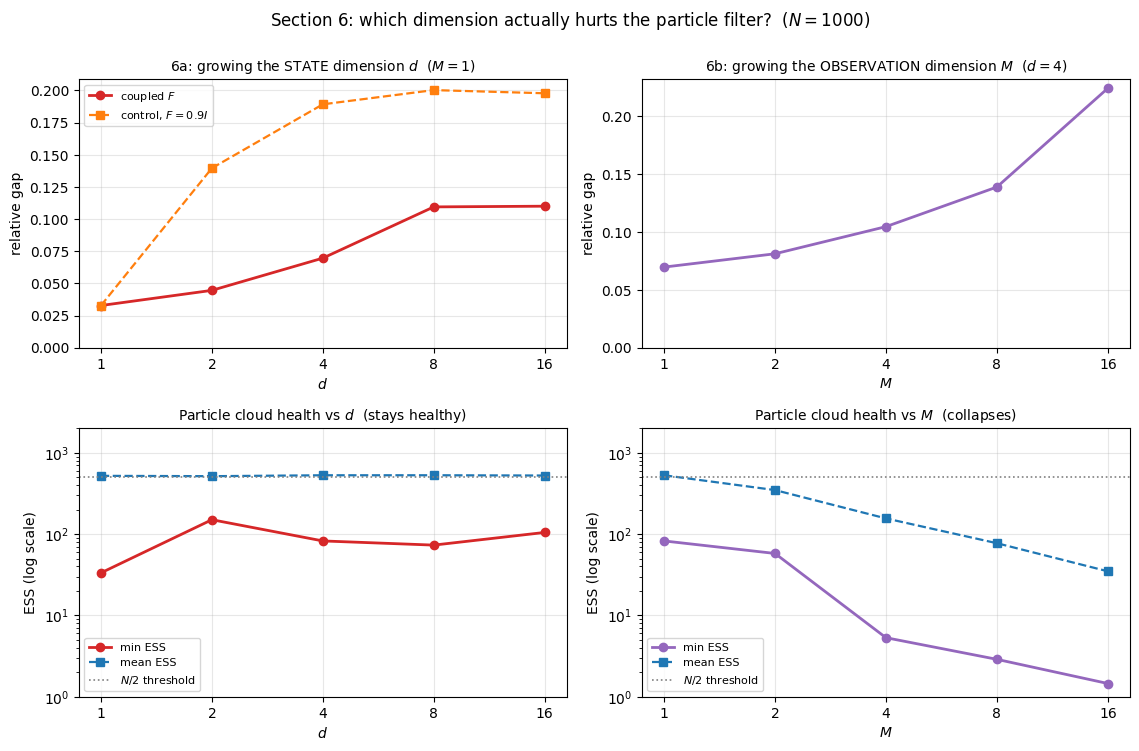

Growing d from 1 to 16 (M=1):   min ESS   33.4 ->  104.9,   relative gap 0.0328 -> 0.1100
Growing M from 1 to 16 (d=4):   min ESS   82.4 ->    1.5,   relative gap 0.0696 -> 0.2241


In [15]:
# --- The comparison that identifies the culprit ---
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5))

# Top-left: relative gap as d grows (M = 1)
ax = axes[0, 0]
ax.plot(D_GRID, [r["rel_gap"] for r in sweep_d], "o-", color="tab:red", lw=2,
        label="coupled $F$")
ax.plot(D_GRID, [r["rel_gap"] for r in sweep_d_ctrl], "s--", color="tab:orange", lw=1.6,
        label="control, $F = 0.9I$")
ax.set_xscale("log", base=2); ax.set_xticks(D_GRID); ax.set_xticklabels(D_GRID)
ax.set_title("6a: growing the STATE dimension $d$  ($M=1$)", fontsize=10)
ax.set_xlabel("$d$"); ax.set_ylabel("relative gap"); ax.legend(fontsize=8)
ax.set_ylim(bottom=0)

# Top-right: relative gap as M grows (d = 4)
ax = axes[0, 1]
ax.plot(M_GRID, [r["rel_gap"] for r in sweep_M], "o-", color="tab:purple", lw=2)
ax.set_xscale("log", base=2); ax.set_xticks(M_GRID); ax.set_xticklabels(M_GRID)
ax.set_title("6b: growing the OBSERVATION dimension $M$  ($d=4$)", fontsize=10)
ax.set_xlabel("$M$"); ax.set_ylabel("relative gap"); ax.set_ylim(bottom=0)

# Bottom-left: ESS as d grows
ax = axes[1, 0]
ax.plot(D_GRID, [r["min_ess"] for r in sweep_d], "o-", color="tab:red", lw=2, label="min ESS")
ax.plot(D_GRID, [r["mean_ess"] for r in sweep_d], "s--", color="tab:blue", lw=1.6, label="mean ESS")
ax.axhline(500, color="grey", ls=":", lw=1.2, label="$N/2$ threshold")
ax.set_xscale("log", base=2); ax.set_xticks(D_GRID); ax.set_xticklabels(D_GRID)
ax.set_yscale("log"); ax.set_ylim(1, 2000)
ax.set_title("Particle cloud health vs $d$  (stays healthy)", fontsize=10)
ax.set_xlabel("$d$"); ax.set_ylabel("ESS (log scale)"); ax.legend(fontsize=8)

# Bottom-right: ESS as M grows
ax = axes[1, 1]
ax.plot(M_GRID, [r["min_ess"] for r in sweep_M], "o-", color="tab:purple", lw=2, label="min ESS")
ax.plot(M_GRID, [r["mean_ess"] for r in sweep_M], "s--", color="tab:blue", lw=1.6, label="mean ESS")
ax.axhline(500, color="grey", ls=":", lw=1.2, label="$N/2$ threshold")
ax.set_xscale("log", base=2); ax.set_xticks(M_GRID); ax.set_xticklabels(M_GRID)
ax.set_yscale("log"); ax.set_ylim(1, 2000)
ax.set_title("Particle cloud health vs $M$  (collapses)", fontsize=10)
ax.set_xlabel("$M$"); ax.set_ylabel("ESS (log scale)"); ax.legend(fontsize=8)

fig.suptitle("Section 6: which dimension actually hurts the particle filter?  ($N = 1000$)", y=0.995)
plt.tight_layout(); plt.show()

print(f"Growing d from 1 to 16 (M=1):   min ESS {sweep_d[0]['min_ess']:6.1f} -> "
      f"{sweep_d[-1]['min_ess']:6.1f},   relative gap {sweep_d[0]['rel_gap']:.4f} -> "
      f"{sweep_d[-1]['rel_gap']:.4f}")
print(f"Growing M from 1 to 16 (d=4):   min ESS {sweep_M[0]['min_ess']:6.1f} -> "
      f"{sweep_M[-1]['min_ess']:6.1f},   relative gap {sweep_M[0]['rel_gap']:.4f} -> "
      f"{sweep_M[-1]['rel_gap']:.4f}")

**Conclusion.** The two sweeps separate as they did in Part 2, but the $d$ sweep is no longer mild.

**Growing $d$ now costs something.** With $M = 1$ held fixed, the relative gap rises from $0.0328$
at $d = 1$ to $0.1100$ at $d = 16$ and the particle cloud stays healthy throughout (minimum ESS
$33$–$105$, mean ESS pinned near $525$). The control with `coupling = 0` is far more severe: the
relative gap reaches $0.1978$ and the posterior spread grows from $0.79$ to $6.51$. That control is
the clearest case — with no coupling and only one coordinate observed, the other $d-1$ coordinates
are independent random walks that nothing ever constrains, so their uncertainty grows without bound.

**Growing $M$ behaves exactly as before.** The minimum ESS collapses from $82.4$ to $1.5$,
resampling fires at every step from $M = 4$ onwards, and the relative gap more than triples to
$0.2241$. Weight degeneracy is driven by the sharpness of the likelihood, and that is unchanged by
the spectral radius.

> **Compared with Part 2 ($\rho(F) = 0.9$).**
>
> | | $\rho = 0.9$ | $\rho = 1$ |
> |---|---|---|
> | rel gap, $d: 1 \to 16$ | $0.033 \to 0.064$, flattening | $0.033 \to \mathbf{0.110}$ |
> | rel gap, control (`coupling=0`) | similar, saturating | $0.033 \to \mathbf{0.198}$ |
> | min ESS vs $d$ | stays healthy | stays healthy |
> | min ESS, $M: 1 \to 16$ | $94 \to 1.3$ | $82 \to 1.5$ |
>
> **The $M$ effect is identical; the $d$ effect roughly doubles.** At $\rho(F) = 0.9$ growing the
> state dimension was mild because every coordinate still forgot its past. At $\rho(F) = 1$ an
> unobserved coordinate forgets nothing, so adding unobserved coordinates adds unbounded
> uncertainty. The damage is still not degeneracy — the cloud stays healthy — it is the amount of
> genuine uncertainty the filter is correctly reporting.

---
## Section 7 — Summary: does stable versus unstable matter?

**Short answer: yes, but only where the observations fail to constrain the state.**

### What is unchanged at $\rho(F) = 1$

**The implementation and the benchmark.** Both verification checks pass to machine precision, as at
$\rho(F) = 0.9$. Nothing in the code depends on the model being stable.

**The $O(1/\sqrt{N})$ Monte Carlo rate.** Fitted slopes $-0.519$, $-0.522$, $-0.483$ against Part 2's
$-0.512$, $-0.520$, $-0.507$. The rate is a property of Monte Carlo and is indifferent to the
spectral radius.

**The $M = d$ baseline.** Relative gap $0.0515$ against $0.0495$; posterior spread $0.7590$ against
$0.7501$. With every coordinate measured, removing the state's tendency to decay changes almost
nothing — the observations alone are enough to keep the posterior bounded.

**The $M > d$ regime.** Relative gap $0.0582$ against $0.0502$, minimum ESS $14.6$ against $15.6$.
Extra observations buy precision in the same way whether the state decays or wanders.

**Degeneracy driven by likelihood sharpness.** Growing $M$ from $1$ to $16$ at $d = 4$ drives the
minimum ESS from $82$ to $1.5$, against $94$ to $1.3$ in Part 2 — the same collapse, unaffected.

### What changes

**$M < d$ gets substantially worse.** The relative gap rises from $0.0568$ to $0.0875$, about $54\%$,
and the error concentrates more sharply in the unmeasured coordinates ($3.45\times$ the measured
ones, against $2.6\times$). This is *after* normalising for the wider posterior, so it is not simply
a harder problem being faithfully reported.

**Growing the state dimension costs about twice as much.** With $M = 1$ fixed, the relative gap at
$d = 16$ reaches $0.1100$ against $0.064$ in Part 2, and $0.1978$ in the uncoupled control against a
saturating curve there.

**Flatness in time is less clear.** Half-run ratios of $1.225$, $1.181$ and $0.988$, against ratios
within a few percent of $1$ at $\rho(F) = 0.9$. One dataset and ten seeds is not enough to call
this, but it is the one place where the threshold might be doing something that $T = 100$ cannot
resolve.

### The pattern

Every effect that gets worse involves **a direction the observations do not constrain**:

| | observations constrain the state? | effect of $\rho(F) = 1$ |
|---|---|---|
| $M = d$ | fully | negligible |
| $M > d$ | fully, with redundancy | negligible |
| $M < d$ | **partially** | **relative gap $+54\%$** |
| $M = 1$, $d$ growing | **less and less** | **relative gap roughly doubles** |
| $M = 1$, $d$ growing, no coupling | **not at all, for $d-1$ coordinates** | **worst case measured** |

At $\rho(F) < 1$ an unobserved coordinate still forgets its past, so its uncertainty settles at a
finite stationary value. At $\rho(F) = 1$ it forgets nothing, and the uncertainty grows without
bound. Whether the model is stable therefore matters exactly insofar as the observations are not
doing the job of keeping the state pinned down.

This is the same conclusion reached independently in
[`05_f_stability_threshold.ipynb`](05_f_stability_threshold.ipynb), where an explosive but
*observed* direction left the posterior bounded while an explosive *unobserved* one did not. It is
also the structure assumed by Del Moral & Gerber (2026), whose conditions require no stability of
the transitions and instead obtain confinement from the observations — at the price of needing
$M \geq d$.

### What this does not settle

- **One dataset.** Part 3 showed that single-dataset comparisons in Part 2 could mislead; the
  half-run ratios above especially need error bars before being interpreted.
- **$T = 100$ is short**, and the rise in the half-run ratios is precisely the kind of thing a
  longer horizon is needed to confirm or dismiss.
- **Only $\rho(F) = 1$ was tested here.** The approach to the threshold
  ($0.99$, $0.995$, $0.999$) is swept in Part 5 for $d = M = 2$, but not for the three regimes.

### Reference

Del Moral, P. & Gerber, M. (2026). *A perturbation theory for Feynman–Kac models and their particle
interpretations.* arXiv:2610.21587.

Gerber, M. & Chopin, N. (2015). *Sequential Quasi-Monte Carlo.* Journal of the Royal Statistical
Society: Series B, 77(3), 509–579.